# CS-317: Reinforcement Learning — Lab 5
## Value Functions, Action-Value Functions and the Bellman Equations
**BS AI-1**

This notebook provides the corridor environment, two policies and a few helper functions. Complete every `# TODO` cell, run all cells top to bottom without errors, and answer the written questions in the markdown cells provided for them.

Some tasks ask you to calculate values **by hand** first. Type your working in the markdown cell provided (a clear photo of handwritten working inserted into the cell is also accepted), then confirm the result in code.

Do not use any reinforcement-learning library (e.g. `gymnasium`, `stable-baselines3`). NumPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

---
## Provided Starter Code

Run the cells in this section as-is. You do not need to modify them, but read `build_corridor` carefully: you will use `P` and `R` in every task below.

In [2]:
# ---------------------------------------------------------------
# Warehouse corridor
#
#   cell:   0     1     2     3     4
#           F     .     S     .     G
#
#   F = forklift zone (terminal)     G = delivery point (terminal)
#   S = start cell (cell 2)
#
# The robot moves one cell in the chosen direction with probability 0.8.
# With probability 0.2 its wheels slip and it stays in the same cell.
# Rewards: +10 for a move that enters G, -10 for a move that enters F,
#          -1 for every other transition (including a slip).
# ---------------------------------------------------------------

ACTIONS = ["Left", "Right"]          # action index 0, 1
N_STATES, N_ACTIONS = 5, 2
TERMINALS = [0, 4]
START = 2
GAMMA = 0.9


def build_corridor(p_move=0.8, step=-1.0, goal=10.0, forklift=-10.0):
    # Builds the tabular MDP for the corridor.
    #
    # Returns
    # -------
    # P : ndarray, shape (5, 2, 5)
    #     P[s, a, s2] = probability of moving from state s to state s2 under action a.
    # R : ndarray, shape (5, 2, 5)
    #     R[s, a, s2] = reward received on that transition.
    #
    # The terminal cells 0 and 4 are absorbing: every action keeps the robot
    # there with probability 1 and reward 0, so their value is always 0.
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    R = np.zeros((N_STATES, N_ACTIONS, N_STATES))

    for t in TERMINALS:
        P[t, :, t] = 1.0                          # absorbing, reward 0

    for s in [1, 2, 3]:
        for a, direction in enumerate([-1, +1]):  # Left = -1, Right = +1
            s2 = s + direction
            if s2 == 4:
                r = goal
            elif s2 == 0:
                r = forklift
            else:
                r = step
            P[s, a, s2] += p_move                 # intended move
            R[s, a, s2] = r
            P[s, a, s] += 1 - p_move              # slip: stay in place
            R[s, a, s] = step
    return P, R


P, R = build_corridor()
print("P has shape", P.shape, "and R has shape", R.shape)
print("Outcomes of action Right in cell 3:")
for s2 in range(N_STATES):
    if P[3, 1, s2] > 0:
        print(f"   next cell {s2}: probability {P[3, 1, s2]:.1f}, reward {R[3, 1, s2]:+.0f}")

P has shape (5, 2, 5) and R has shape (5, 2, 5)
Outcomes of action Right in cell 3:
   next cell 3: probability 0.2, reward -1
   next cell 4: probability 0.8, reward +10


In [3]:
# The two policies used in this lab, stored as pi[s, a] = probability of action a in state s.
# (The rows of the terminal cells are never used.)

right_policy = np.zeros((N_STATES, N_ACTIONS))
right_policy[:, 1] = 1.0                       # Always-Right policy  (pi_R)

random_policy = np.full((N_STATES, N_ACTIONS), 0.5)   # Random policy (pi_U)

print("pi_R:\n", right_policy)
print("pi_U:\n", random_policy)

pi_R:
 [[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]
pi_U:
 [[0.5 0.5]
 [0.5 0.5]
 [0.5 0.5]
 [0.5 0.5]
 [0.5 0.5]]


Demo episode under pi_R
  states : [2, 3, 3, 4]
  actions: ['Right', 'Right', 'Right']
  rewards: [-1.0, -1.0, 10.0]


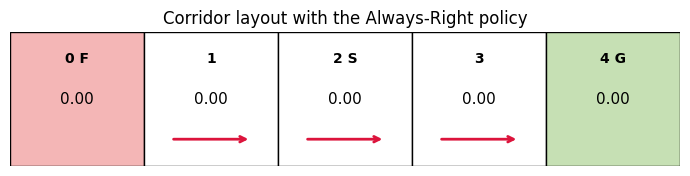

In [4]:
def sample_episode(policy, start=START, rng=None, max_steps=100, P=P, R=R):
    # Runs one episode from `start` following `policy` (shape (5, 2)).
    # Returns three lists: the visited states, the chosen actions, and the rewards.
    if rng is None:
        rng = np.random.default_rng()
    s = start
    states, actions, rewards = [s], [], []
    for _ in range(max_steps):
        a = rng.choice(N_ACTIONS, p=policy[s])
        s2 = rng.choice(N_STATES, p=P[s, a])
        actions.append(int(a))
        rewards.append(float(R[s, a, s2]))
        states.append(int(s2))
        s = s2
        if s in TERMINALS:
            break
    return states, actions, rewards


def plot_corridor(V, policy=None, title=""):
    # Draws the corridor with the value of each cell written inside it.
    # `policy` (optional) may be an array of action indices, shape (5,),
    # or a policy matrix, shape (5, 2); an arrow is drawn for the chosen action.
    V = np.asarray(V, dtype=float)
    labels = ["F", "", "S", "", "G"]
    colours = ["#f4b6b6", "white", "white", "white", "#c6e0b4"]
    fig, ax = plt.subplots(figsize=(7, 1.8))
    for c in range(N_STATES):
        ax.add_patch(plt.Rectangle((c - 0.5, -0.5), 1, 1, facecolor=colours[c], edgecolor="black"))
        ax.text(c, 0.3, f"{c} {labels[c]}".strip(), ha="center", va="center", fontsize=10, fontweight="bold")
        ax.text(c, 0.0, f"{V[c]:.2f}", ha="center", va="center", fontsize=11)
    if policy is not None:
        pol = np.asarray(policy)
        acts = pol.argmax(axis=1) if pol.ndim == 2 else pol
        for c in [1, 2, 3]:
            dx = -0.3 if acts[c] == 0 else 0.3
            ax.annotate("", xy=(c + dx, -0.3), xytext=(c - dx, -0.3),
                        arrowprops=dict(arrowstyle="->", lw=2, color="crimson"))
    ax.set_xlim(-0.5, N_STATES - 0.5); ax.set_ylim(-0.5, 0.5)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
    plt.tight_layout(); plt.show()


demo_states, demo_actions, demo_rewards = sample_episode(right_policy, rng=np.random.default_rng(0))
print("Demo episode under pi_R")
print("  states :", demo_states)
print("  actions:", [ACTIONS[a] for a in demo_actions])
print("  rewards:", demo_rewards)
plot_corridor(np.zeros(N_STATES), policy=right_policy, title="Corridor layout with the Always-Right policy")

---
## Part 1: Returns and the State-Value Function  *(25 min)*

The **return** is $G_t=R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots$.

### Task 1: Compute Returns by Hand

| Episode | State sequence | Rewards | $G_0$ ($\gamma=0.9$) | $G_0$ ($\gamma=0.5$) |
|---|---|---|---:|---:|
| A | 2 $\to$ 3 $\to$ G | $[-1,10]$ | $-1+0.9(10)=8.000$ | $-1+0.5(10)=4.000$ |
| B | 2 $\to$ 2 $\to$ 3 $\to$ 3 $\to$ G | $[-1,-1,-1,10]$ | $-1-0.9-0.9^2+0.9^3(10)=4.580$ | $-1-0.5-0.5^2+0.5^3(10)=-0.500$ |
| C | 2 $\to$ 1 $\to$ F | $[-1,-10]$ | $-1+0.9(-10)=-10.000$ | $-1+0.5(-10)=-6.000$ |


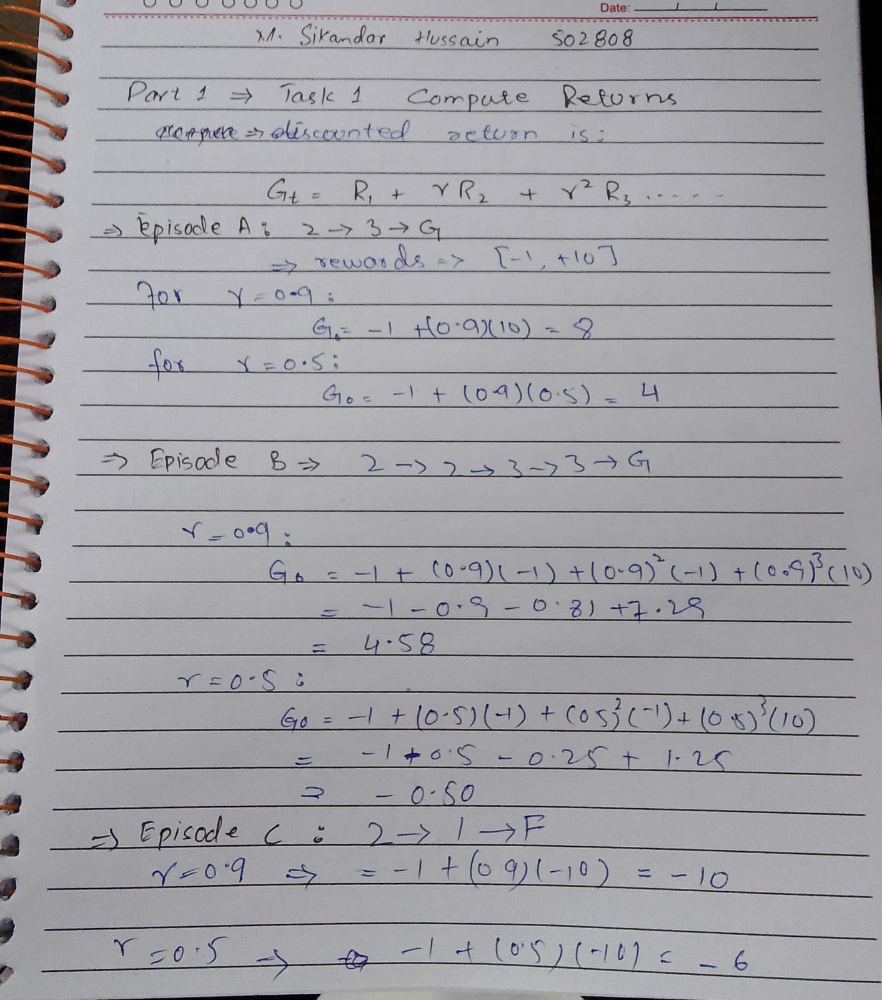

### Task 2: Implement the Return

In [5]:
def discounted_return(rewards, gamma):
    """Return G_0 = r_1 + gamma*r_2 + gamma^2*r_3 + ..."""
    G = 0.0
    for reward in reversed(rewards):
        G = reward + gamma * G
    return G


episodes = {
    "A": [-1, 10],
    "B": [-1, -1, -1, 10],
    "C": [-1, -10],
}

for name, rewards in episodes.items():
    for gamma in (0.9, 0.5):
        print(f"Episode {name}, gamma={gamma}: G0={discounted_return(rewards, gamma):.3f}")


Episode A, gamma=0.9: G0=8.000
Episode A, gamma=0.5: G0=4.000
Episode B, gamma=0.9: G0=4.580
Episode B, gamma=0.5: G0=-0.500
Episode C, gamma=0.9: G0=-10.000
Episode C, gamma=0.5: G0=-6.000


### Task 3: Estimate the Value Function from Episodes

Because $V^\pi(s)$ is an *expected* return, it can be approximated by averaging the returns of many episodes. Implement `estimate_value`, then estimate $V(2)$ for both policies with 10, 100 and 1000 episodes.

In [6]:
def estimate_value(policy, start, n_episodes, gamma, seed=42):
    """Monte Carlo estimate: average return from repeated sampled episodes."""
    rng = np.random.default_rng(seed)
    returns = []
    for _ in range(n_episodes):
        _, _, rewards = sample_episode(policy, start=start, rng=rng)
        returns.append(discounted_return(rewards, gamma))
    return float(np.mean(returns))


mc_estimates = {}
for n in (10, 100, 1000):
    v_right = estimate_value(right_policy, START, n, GAMMA, seed=42)
    v_random = estimate_value(random_policy, START, n, GAMMA, seed=42)
    mc_estimates[n] = (v_right, v_random)
    print(f"n={n:4d}: V_piR(2)={v_right:8.3f}, V_piU(2)={v_random:8.3f}")


n=  10: V_piR(2)=   7.298, V_piU(2)=  -0.319
n= 100: V_piR(2)=   7.156, V_piU(2)=  -3.274


n=1000: V_piR(2)=   7.105, V_piU(2)=  -3.062


| Episodes | Estimate of $V^{\pi_R}(2)$ | Estimate of $V^{\pi_U}(2)$ |
|---:|---:|---:|
| 10 | 7.298 | -0.319 |
| 100 | 7.156 | -3.274 |
| 1000 | 7.105 | -3.062 |

**Questions**

1. Episode B contains two slips. It therefore receives more step penalties, and its positive terminal reward arrives later and is discounted more heavily, so its return is lower than A's.

2. Reducing $\gamma$ from 0.9 to 0.5 reduces the weight on later rewards. The delayed goal reward in B loses so much weight that its return becomes negative; C becomes less negative because its future forklift penalty is also discounted more. Thus a smaller $\gamma$ makes the robot more short-sighted.

3. Sampling produces random trajectories, so a finite-sample mean has sampling error. As the number of episodes grows, unusually lucky and unlucky episodes tend to average out. I would trust the 1000-episode estimates most because they normally have the lowest variance.


---
## Part 2: The Bellman Expectation Equation  *(40 min)*

For a fixed policy,
$$V^\pi(s)=\sum_a\pi(a|s)\sum_{s'}P(s'|s,a)[R(s,a,s')+\gamma V^\pi(s')].$$

### Task 1: Solve by Hand

Under Always-Right, with $V(0)=V(4)=0$ and $\gamma=0.9$:

$$V(3)=0.8(10)+0.2[-1+0.9V(3)]$$
$$0.82V(3)=7.8 \quad\Rightarrow\quad V(3)=9.512.$$

$$V(2)=0.8[-1+0.9V(3)]+0.2[-1+0.9V(2)]$$
$$0.82V(2)=-1+0.72V(3) \quad\Rightarrow\quad V(2)=7.133.$$

$$V(1)=0.8[-1+0.9V(2)]+0.2[-1+0.9V(1)]$$
$$0.82V(1)=-1+0.72V(2) \quad\Rightarrow\quad V(1)=5.043.$$


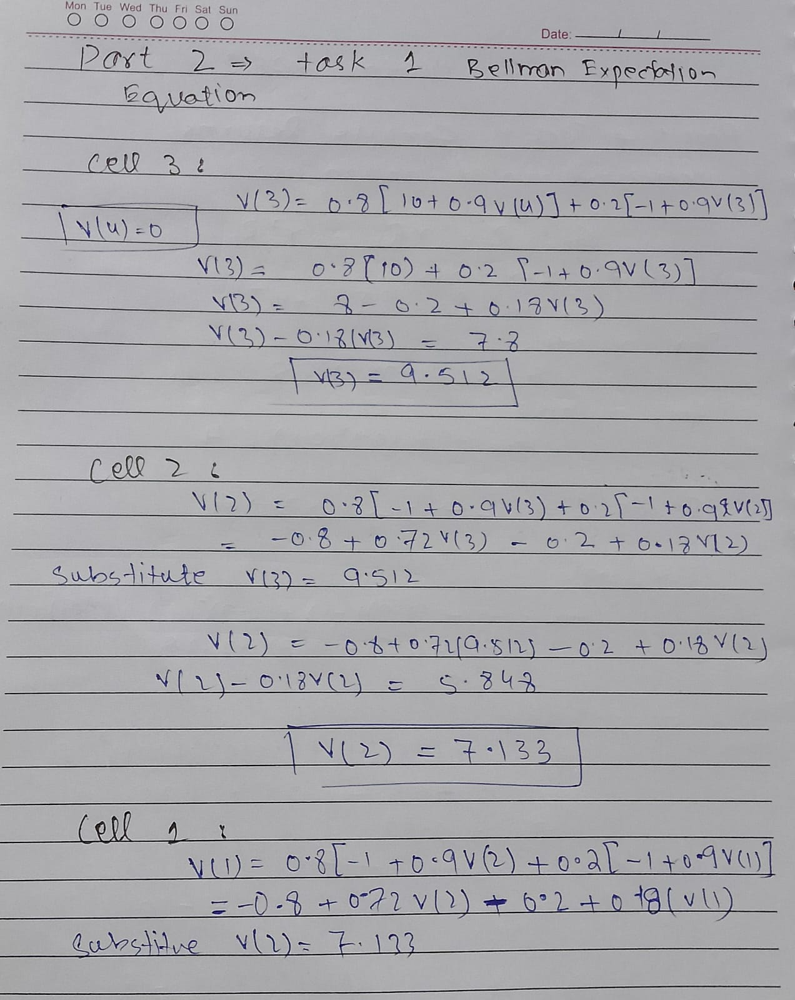
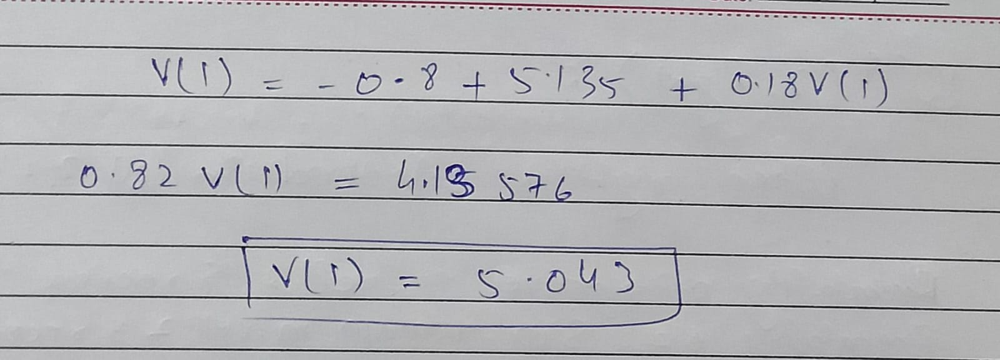

### Task 2: Solve the Bellman Equation in Code

For all states together, the Bellman expectation equation is the linear system $V = r_\pi + \gamma P_\pi V$, i.e. $(I - \gamma P_\pi)\,V = r_\pi$.

In [7]:
def bellman_solve(P, R, policy, gamma):
    """Solve (I - gamma P_pi)V = r_pi exactly."""
    P_pi = np.einsum("sa,san->sn", policy, P)
    r_pi = np.einsum("sa,san,san->s", policy, P, R)
    return np.linalg.solve(np.eye(P.shape[0]) - gamma * P_pi, r_pi)


V_right_exact = bellman_solve(P, R, right_policy, GAMMA)
V_random_exact = bellman_solve(P, R, random_policy, GAMMA)
print("V_piR =", V_right_exact)
print("V_piU =", V_random_exact)


V_piR = [0.    5.043 7.133 9.512 0.   ]
V_piU = [-0.    -6.94  -3.03   2.816  0.   ]


### Task 3: Iterative Policy Evaluation (Dynamic Programming)

Start with $V = 0$ and repeatedly apply the Bellman expectation equation as an update:

$$V_{k+1}(s) = \sum_{a} \pi(a|s) \sum_{s'} P(s'|s,a)\,\left[\,R(s,a,s') + \gamma V_k(s')\,\right]$$

Stop when $\max_s |V_{k+1}(s) - V_k(s)| < 10^{-6}$.

Always-Right policy evaluation
Sweep 1: [ 0.  -1.  -1.   7.8  0. ]
Sweep 2: [ 0.    -1.9    4.436  9.204  0.   ]
Sweep 3: [0.    1.852 6.425 9.457 0.   ]
Converged in 15 sweeps; V_piR = [0.    5.043 7.133 9.512 0.   ]


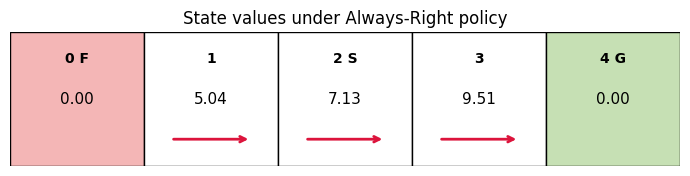

Random policy evaluation
Sweep 1: [ 0.  -4.6 -1.   3.4  0. ]
Sweep 2: [ 0.    -5.788 -1.612  3.652  0.   ]
Sweep 3: [ 0.    -6.222 -2.059  3.477  0.   ]
Converged in 38 sweeps; V_piU = [ 0.    -6.94  -3.03   2.816  0.   ]


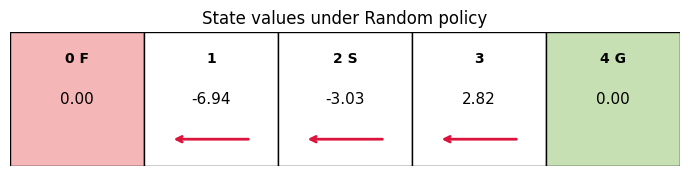

In [8]:
def policy_evaluation(P, R, policy, gamma, theta=1e-6, verbose=False):
    """Synchronous iterative policy evaluation."""
    V = np.zeros(P.shape[0])
    n_sweeps = 0
    while True:
        V_new = np.einsum("sa,san,san->s", policy, P, R + gamma * V[None, None, :])
        n_sweeps += 1
        if verbose and n_sweeps <= 3:
            print(f"Sweep {n_sweeps}: {V_new}")
        delta = np.max(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            return V, n_sweeps


print("Always-Right policy evaluation")
V_right, sweeps_right = policy_evaluation(P, R, right_policy, GAMMA, verbose=True)
print(f"Converged in {sweeps_right} sweeps; V_piR = {V_right}")
plot_corridor(V_right, right_policy, "State values under Always-Right policy")

print("Random policy evaluation")
V_random, sweeps_random = policy_evaluation(P, R, random_policy, GAMMA, verbose=True)
print(f"Converged in {sweeps_random} sweeps; V_piU = {V_random}")
plot_corridor(V_random, random_policy, "State values under Random policy")


| Cell | $V^{\pi_R}$ (by hand) | $V^{\pi_R}$ (DP) | $V^{\pi_U}$ (DP) |
|---:|---:|---:|---:|
| 1 | 5.043 | 5.043 | -6.940 |
| 2 | 7.133 | 7.133 | -3.030 |
| 3 | 9.512 | 9.512 | 2.816 |

**Questions**

1. The Monte Carlo estimates approach the DP values but are only approximate because they average a finite set of random episodes. DP uses the complete known transition model and solves the expectation to numerical tolerance, so it has no sampling error.

2. Cell 1 has the lowest non-terminal value ($-6.940$). It is adjacent to the forklift terminal, and the random policy chooses Left half the time, creating a substantial chance of the $-10$ reward.

3. The Bellman expectation equation says that a state's value is the policy-weighted average of each possible immediate reward plus the discounted value of the next state, accounting for transition uncertainty.


---
## Part 3: The Action-Value Function  *(35 min)*

$$Q^\pi(s,a)=\sum_{s'}P(s'|s,a)[R(s,a,s')+\gamma V^\pi(s')],\qquad
V^\pi(s)=\sum_a\pi(a|s)Q^\pi(s,a).$$

### Task 1: Compute by Hand

Using $V^{\pi_R}(1)=5.043$, $V^{\pi_R}(2)=7.133$, and $V^{\pi_R}(3)=9.512$:

$$Q^{\pi_R}(2,L)=0.8[-1+0.9(5.043)]+0.2[-1+0.9(7.133)]=3.915.$$

$$Q^{\pi_R}(2,R)=0.8[-1+0.9(9.512)]+0.2[-1+0.9(7.133)]=7.133.$$


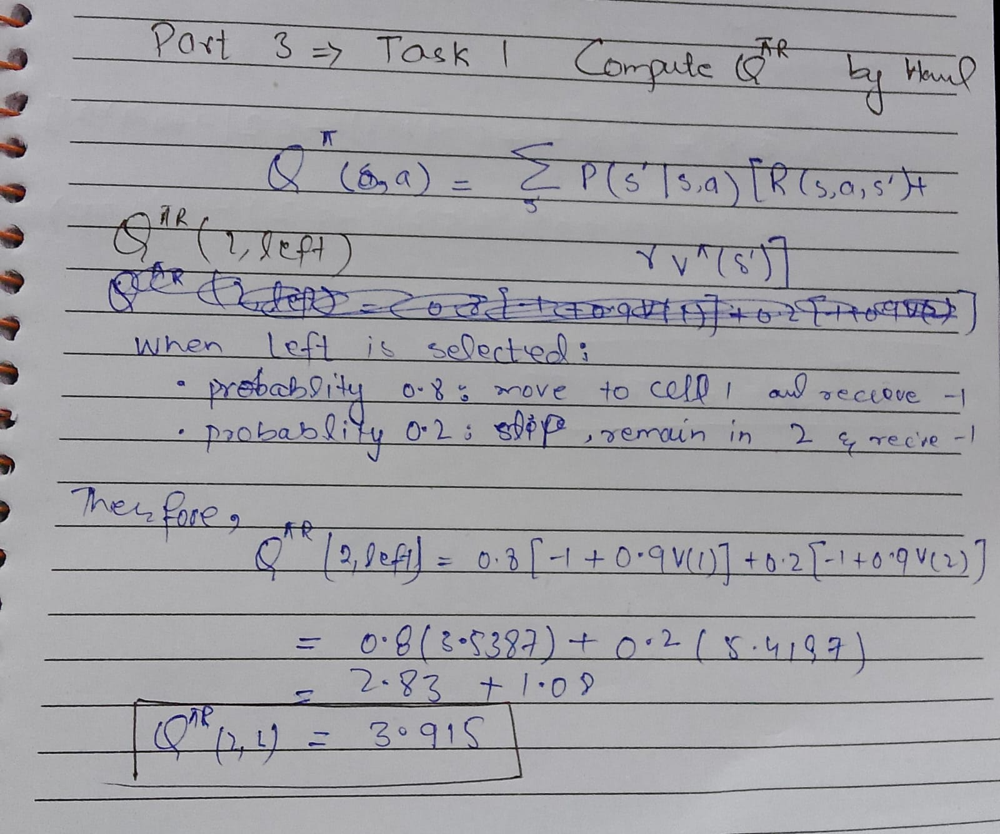
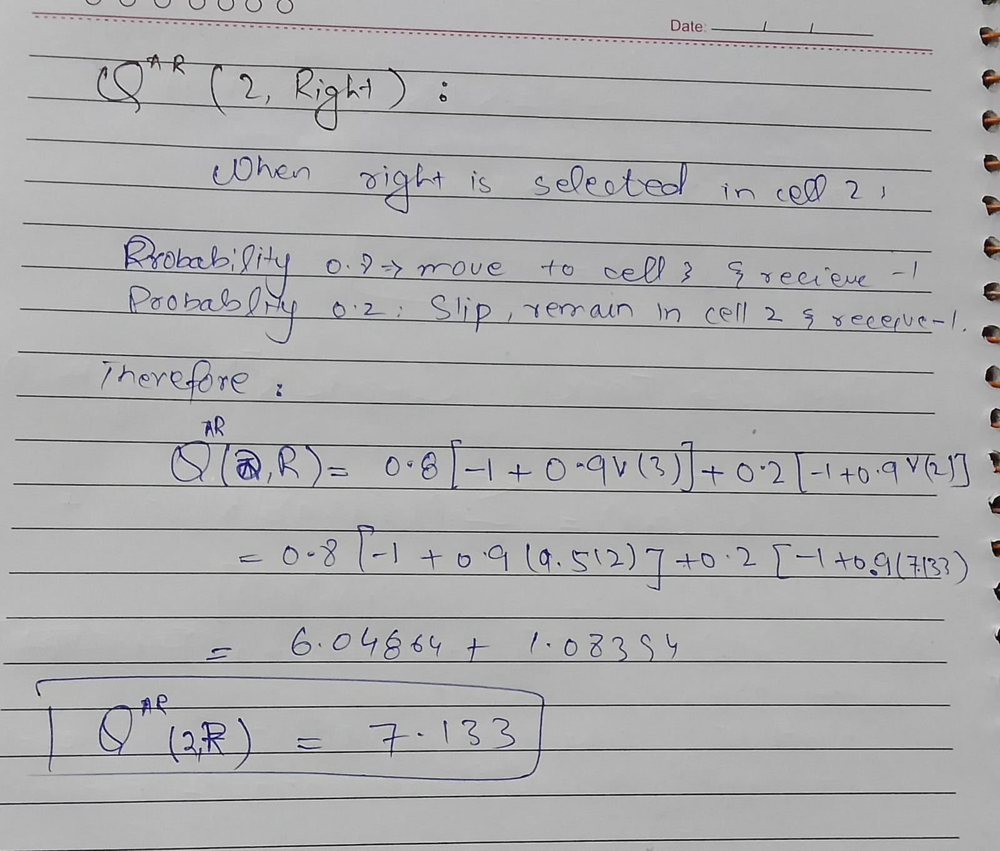

### Task 2: Compute Q in Code

In [9]:
def q_from_v(P, R, V, gamma):
    """Compute Q[s,a] by one-step lookahead from V."""
    return np.sum(P * (R + gamma * V[None, None, :]), axis=2)


Q_right = q_from_v(P, R, V_right, GAMMA)
Q_random = q_from_v(P, R, V_random, GAMMA)
print("Q_piR (columns: Left, Right):\n", Q_right)
print("Q_piU (columns: Left, Right):\n", Q_random)


Q_piR (columns: Left, Right):
 [[ 0.     0.   ]
 [-7.292  5.043]
 [ 3.915  7.133]
 [ 5.848  9.512]
 [ 0.     0.   ]]
Q_piU (columns: Left, Right):
 [[ 0.     0.   ]
 [-9.449 -4.431]
 [-6.542  0.482]
 [-2.675  8.307]
 [ 0.     0.   ]]


| Cell | $Q^{\pi_R}(s,L)$ | $Q^{\pi_R}(s,R)$ | $Q^{\pi_U}(s,L)$ | $Q^{\pi_U}(s,R)$ |
|---:|---:|---:|---:|---:|
| 1 | -7.292 | 5.043 | -9.449 | -4.431 |
| 2 | 3.915 | 7.133 | -6.542 | 0.482 |
| 3 | 5.848 | 9.512 | -2.675 | 8.307 |

### Task 3: Check the Relationship Between V and Q

The following code verifies $V^\pi(s)=\sum_a\pi(a|s)Q^\pi(s,a)$ in every state.


In [10]:
for name, policy, Q, V in [
    ("Always-Right", right_policy, Q_right, V_right),
    ("Random", random_policy, Q_random, V_random),
]:
    reconstructed_V = (policy * Q).sum(axis=1)
    max_difference = np.max(np.abs(reconstructed_V - V))
    print(f"{name}: reconstructed V = {reconstructed_V}")
    print(f"{name}: maximum absolute difference = {max_difference:.3e}")


Always-Right: reconstructed V = [0.    5.043 7.133 9.512 0.   ]
Always-Right: maximum absolute difference = 8.800e-08
Random: reconstructed V = [ 0.    -6.94  -3.03   2.816  0.   ]
Random: maximum absolute difference = 6.621e-07


**Questions**

1. $V^{\pi_R}(2)$ averages action values using the policy. Always-Right selects Right with probability 1, so its state value equals $Q^{\pi_R}(2,Right)$. Left is never selected by this policy, and its Q-value evaluates a different first action before returning to Always-Right.

2. Under $\pi_U$, Right has the higher Q-value in cells 1, 2, and 3. Always choosing the higher-valued action gives the Always-Right policy.

3. $V(s)$ evaluates a state under a policy but does not separately show the consequences of each choice. $Q(s,a)$ scores every available action, so the robot can compare them directly and choose an action with the largest value.


---
## Part 4: The Optimal Value Function and the Bellman Optimality Equation  *(40 min)*

### Task 1: Write the Optimality Equations

With $V^*(0)=V^*(4)=0$, the two expressions in each maximum correspond to Left and Right:

$$V^*(1)=\max\left\{
0.8(-10)+0.2[-1+0.9V^*(1)],\;
0.8[-1+0.9V^*(2)]+0.2[-1+0.9V^*(1)]
\right\}.$$

$$V^*(2)=\max\left\{
0.8[-1+0.9V^*(1)]+0.2[-1+0.9V^*(2)],\;
0.8[-1+0.9V^*(3)]+0.2[-1+0.9V^*(2)]
\right\}.$$

$$V^*(3)=\max\left\{
0.8[-1+0.9V^*(2)]+0.2[-1+0.9V^*(3)],\;
0.8(10)+0.2[-1+0.9V^*(3)]
\right\}.$$


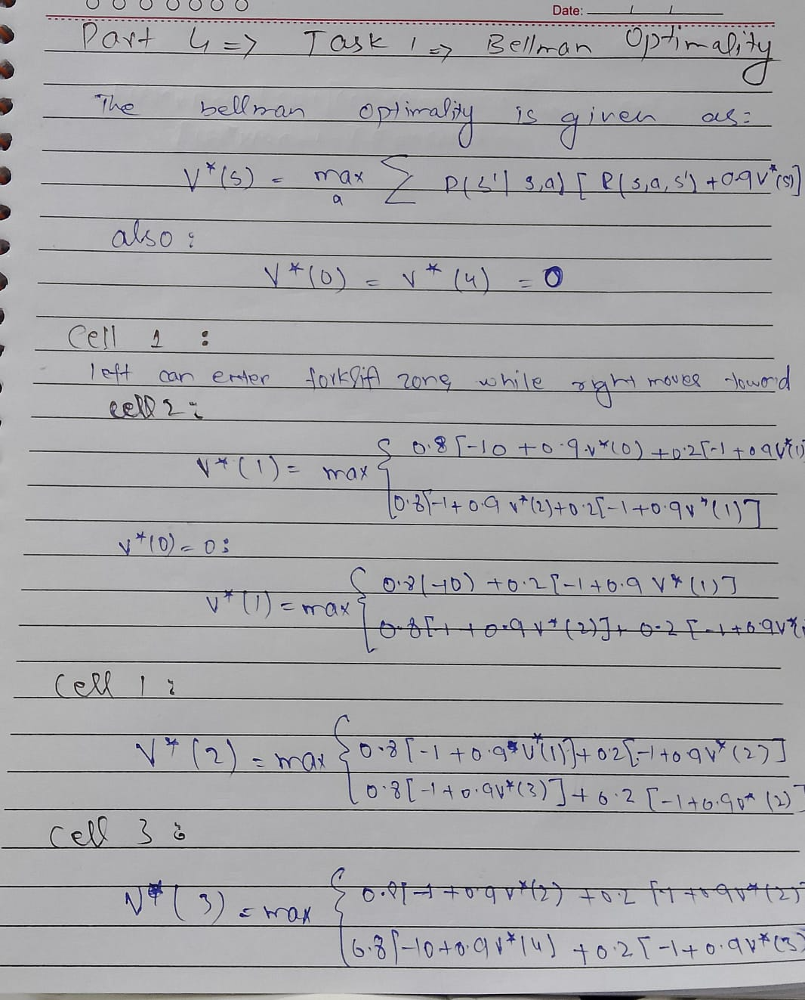
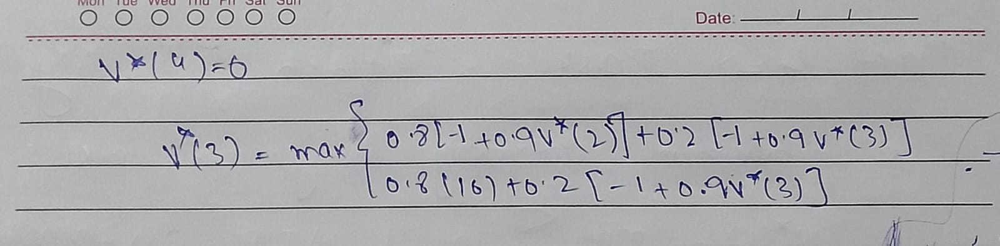

### Task 2: Value Iteration (Dynamic Programming)

Start with $V = 0$ and repeatedly apply the Bellman optimality equation as an update:

$$V_{k+1}(s) = \max_{a} \sum_{s'} P(s'|s,a)\,\left[\,R(s,a,s') + \gamma V_k(s')\,\right]$$

Stop when $\max_s |V_{k+1}(s) - V_k(s)| < 10^{-6}$.

In [11]:
def value_iteration(P, R, gamma, theta=1e-6, verbose=False):
    """Synchronous value iteration using Bellman optimality backups."""
    V = np.zeros(P.shape[0])
    n_sweeps = 0
    while True:
        V_new = q_from_v(P, R, V, gamma).max(axis=1)
        n_sweeps += 1
        if verbose and n_sweeps <= 3:
            print(f"Sweep {n_sweeps}: {V_new}")
        delta = np.max(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            return V, n_sweeps


V_star, n_sweeps_vi = value_iteration(P, R, GAMMA, verbose=True)
print(f"Value Iteration converged in {n_sweeps_vi} sweeps")
print("V* =", V_star)


Sweep 1: [ 0.  -1.  -1.   7.8  0. ]
Sweep 2: [ 0.    -1.9    4.436  9.204  0.   ]
Sweep 3: [0.    1.852 6.425 9.457 0.   ]
Value Iteration converged in 15 sweeps
V* = [0.    5.043 7.133 9.512 0.   ]


### Task 3: Optimal Action Values and Optimal Policy

Q* (columns: Left, Right):
 [[ 0.     0.   ]
 [-7.292  5.043]
 [ 3.915  7.133]
 [ 5.848  9.512]
 [ 0.     0.   ]]
Optimal action in cell 1: Right
Optimal action in cell 2: Right
Optimal action in cell 3: Right
max |V* - max_a Q*| = 8.800e-08


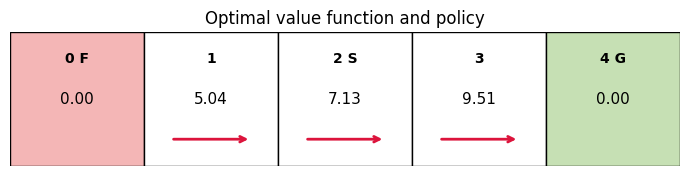

In [12]:
Q_star = q_from_v(P, R, V_star, GAMMA)
pi_star = Q_star.argmax(axis=1)

print("Q* (columns: Left, Right):\n", Q_star)
for s in (1, 2, 3):
    print(f"Optimal action in cell {s}: {ACTIONS[pi_star[s]]}")

optimality_difference = np.max(np.abs(V_star - Q_star.max(axis=1)))
print(f"max |V* - max_a Q*| = {optimality_difference:.3e}")
plot_corridor(V_star, pi_star, "Optimal value function and policy")


| Cell | $V^{\pi_U}(s)$ | $V^{\pi_R}(s)$ | $V^*(s)$ | $Q^*(s,L)$ | $Q^*(s,R)$ | $\pi^*(s)$ |
|---:|---:|---:|---:|---:|---:|---|
| 1 | -6.940 | 5.043 | 5.043 | -7.292 | 5.043 | Right |
| 2 | -3.030 | 7.133 | 7.133 | 3.915 | 7.133 | Right |
| 3 | 2.816 | 9.512 | 9.512 | 5.848 | 9.512 | Right |

**Questions**

1. Yes. $V^*(s)$ is defined as the maximum expected return achievable from state $s$ over all policies. Therefore it cannot be smaller than the value achieved by either particular policy. Equality is possible when that policy is optimal from the state.

2. Always-Right is optimal. Its action in every non-terminal cell matches $\pi^*$. This also matches the greedy policy derived from $Q^{\pi_U}$ in Part 3: choosing Right in every cell.

3. The Bellman expectation equation evaluates a fixed policy by taking a policy-weighted average over actions. The Bellman optimality equation instead takes the maximum over actions, so it identifies the best achievable value and induces an optimal policy.


---
## Part 5: Summary of Concepts  *(15 min)*

### Task 1: Complete the Table

| Function | What it measures | Bellman equation (in words) | How it was computed in this lab |
|---|---|---|---|
| $V^\pi(s)$ | Expected return from state $s$ while following $\pi$ | Policy-weighted average of immediate reward plus discounted next-state value | Monte Carlo estimation, a linear-system solution, and iterative policy evaluation |
| $Q^\pi(s,a)$ | Expected return after taking $a$ in $s$, then following $\pi$ | Transition-weighted immediate reward plus discounted $V^\pi$ of the next state | One-step lookahead from $V^\pi$ using `q_from_v` |
| $V^*(s)$ | Best expected return achievable from $s$ | Maximum across actions of immediate reward plus discounted optimal next-state value | Value iteration |
| $Q^*(s,a)$ | Return from taking $a$ in $s$ and behaving optimally afterward | Transition-weighted immediate reward plus discounted $V^*$ of the next state | One-step lookahead from $V^*$ using `q_from_v` |

### Task 2: Reflection

For a fixed policy, $Q^\pi(s,a)$ evaluates taking action $a$ once and then following $\pi$; $V^\pi(s)$ is the policy-weighted average of these action values. Thus $V^\pi$ summarizes how good the state is under the policy, while $Q^\pi$ separates the available choices. For the optimal case, $V^*(s)=\max_a Q^*(s,a)$, and an optimal policy selects an action attaining that maximum. Both functions use the same immediate rewards and discounted next-state values, but $Q$ makes action selection explicit.
